# EDA

# EDA Using Pandas

# 1 dim_date

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

C:\Users\Lenovo\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


# Basic structure

In [3]:
import pandas as pd
from pathlib import Path

csv_path = Path.home() / "Desktop" / "csv"

print(csv_path)

C:\Users\Lenovo\Desktop\csv


In [4]:
dim_date = pd.read_csv(csv_path / "dim_date.csv")
dim_department = pd.read_csv(csv_path / "dim_department.csv")
dim_employee = pd.read_csv(csv_path / "dim_employee.csv")
dim_employee_snapshot = pd.read_csv(csv_path / "dim_employee_snapshot.csv")
dim_job_role = pd.read_csv(csv_path / "dim_job_role.csv")
fact_attrition = pd.read_csv(csv_path / "fact_attrition.csv")

In [5]:
print("dim_date:", dim_date.shape)
print("dim_department:", dim_department.shape)
print("dim_employee:", dim_employee.shape)
print("dim_employee_snapshot:", dim_employee_snapshot.shape)
print("dim_job_role:", dim_job_role.shape)
print("fact_attrition:", fact_attrition.shape)

dim_date: (4383, 10)
dim_department: (10, 2)
dim_employee: (45000, 13)
dim_employee_snapshot: (45000, 26)
dim_job_role: (23, 4)
fact_attrition: (4231, 11)


In [6]:
dim_date.shape

(4383, 10)

In [7]:
dim_date.head()

,DateID,Date,Year,Quarter,MonthNumber,MonthName,MonthYear,WeekNumber,DayName,IsWeekend
0,20150101,2015-01-01,2015,Q1,1,January,Jan-2015,1,Thursday,False
1,20150102,2015-01-02,2015,Q1,1,January,Jan-2015,1,Friday,False
2,20150103,2015-01-03,2015,Q1,1,January,Jan-2015,1,Saturday,True
3,20150104,2015-01-04,2015,Q1,1,January,Jan-2015,1,Sunday,True
4,20150105,2015-01-05,2015,Q1,1,January,Jan-2015,2,Monday,False


In [8]:
dim_date.tail()

,DateID,Date,Year,Quarter,MonthNumber,MonthName,MonthYear,WeekNumber,DayName,IsWeekend
4378,20261227,2026-12-27,2026,Q4,12,December,Dec-2026,52,Sunday,True
4379,20261228,2026-12-28,2026,Q4,12,December,Dec-2026,53,Monday,False
4380,20261229,2026-12-29,2026,Q4,12,December,Dec-2026,53,Tuesday,False
4381,20261230,2026-12-30,2026,Q4,12,December,Dec-2026,53,Wednesday,False
4382,20261231,2026-12-31,2026,Q4,12,December,Dec-2026,53,Thursday,False


In [9]:
dim_date.info()

<class 'pandas.DataFrame'>
RangeIndex: 4383 entries, 0 to 4382
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   DateID       4383 non-null   int64
 1   Date         4383 non-null   str  
 2   Year         4383 non-null   int64
 3   Quarter      4383 non-null   str  
 4   MonthNumber  4383 non-null   int64
 5   MonthName    4383 non-null   str  
 6   MonthYear    4383 non-null   str  
 7   WeekNumber   4383 non-null   int64
 8   DayName      4383 non-null   str  
 9   IsWeekend    4383 non-null   bool 
dtypes: bool(1), int64(4), str(5)
memory usage: 455.1 KB


In [10]:
dim_date.isna().sum()

DateID         0
Date           0
Year           0
Quarter        0
MonthNumber    0
MonthName      0
MonthYear      0
WeekNumber     0
DayName        0
IsWeekend      0
dtype: int64

In [11]:
dim_date.nunique()

DateID         4383
Date           4383
Year             12
Quarter           4
MonthNumber      12
MonthName        12
MonthYear       144
WeekNumber       53
DayName           7
IsWeekend         2
dtype: int64

# 2 dim_department

In [12]:
dim_department.shape

(10, 2)

In [13]:
dim_department.head()

,DepartmentID,DepartmentName
0,D01,Human Resources
1,D02,Finance
2,D03,Sales
3,D04,Marketing
4,D05,Information Technology


# Categorical distribution

In [14]:
for col in dim_department.select_dtypes(include="object").columns:
    print(f"\n===== {col} =====")
    print(dim_department[col].value_counts(dropna=False))


===== DepartmentID =====
DepartmentID
D01    1
D02    1
D03    1
D04    1
D05    1
D06    1
D07    1
D08    1
D09    1
D10    1
Name: count, dtype: int64

===== DepartmentName =====
DepartmentName
Human Resources           1
Finance                   1
Sales                     1
Marketing                 1
Information Technology    1
Operations                1
Customer Service          1
Research & Development    1
Legal                     1
Procurement               1
Name: count, dtype: int64


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_15952\3121551627.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in dim_department.select_dtypes(include="object").columns:


# Bar charts

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_15952\1634829950.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in dim_department.select_dtypes(include="object").columns:


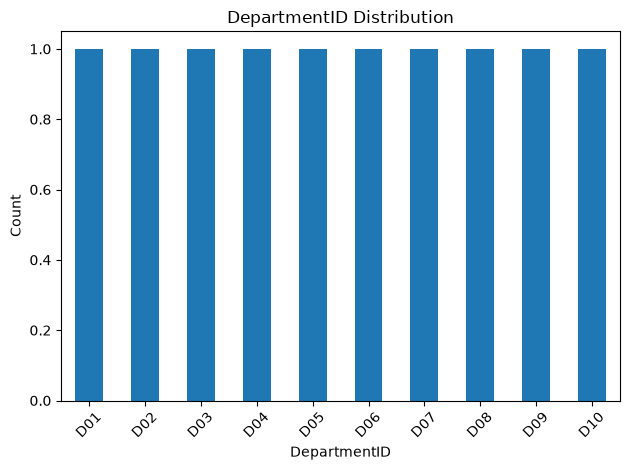

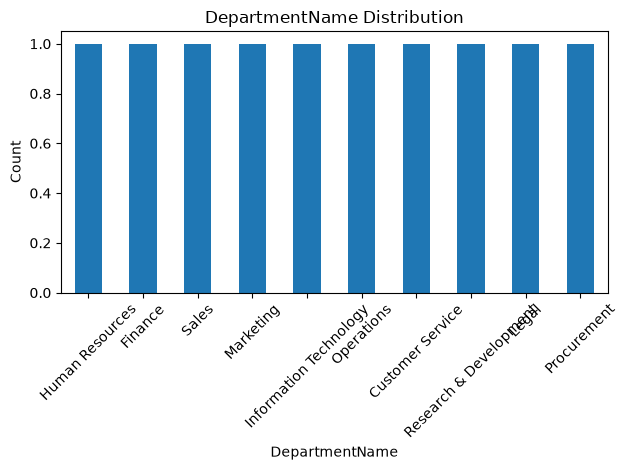

In [15]:
for col in dim_department.select_dtypes(include="object").columns:

    dim_department[col].value_counts(dropna=False).plot(
        kind="bar"
    )

    plt.title(f"{col} Distribution")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# 3 dim_employee

# Age

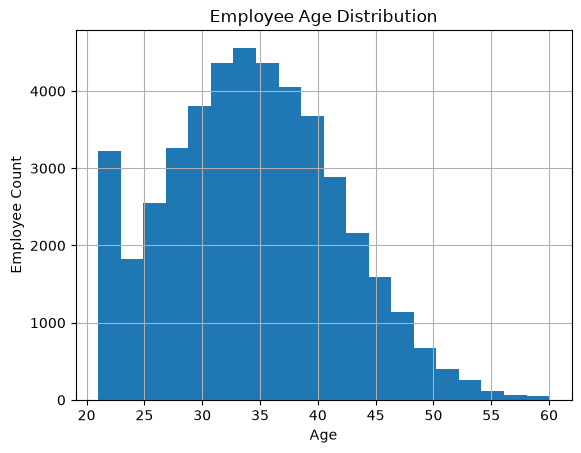

In [16]:
dim_employee["Age"].hist(bins=20)

plt.title("Employee Age Distribution")
plt.xlabel("Age")
plt.ylabel("Employee Count")
plt.show()

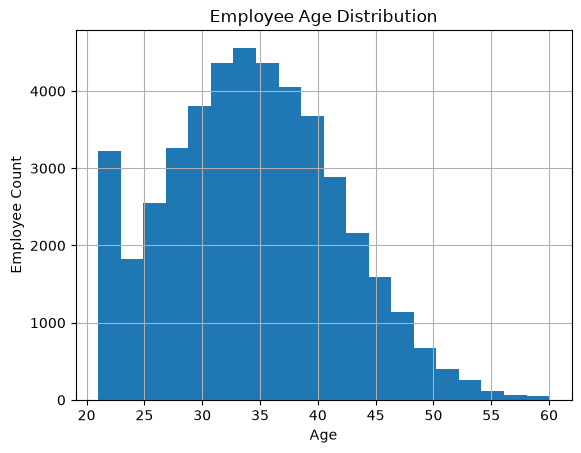

In [17]:
dim_employee["Age"].hist(bins=20)

plt.title("Employee Age Distribution")
plt.xlabel("Age")
plt.ylabel("Employee Count")
plt.show()

# 4 dim_employee_snapshot

In [18]:
dim_employee_snapshot.columns.tolist()

['EmployeeID',
 'DepartmentID',
 'JobRoleID',
 'City',
 'EmploymentType',
 'HireDate',
 'ExitDate',
 'Status',
 'Attrition',
 'Age',
 'YearsAtCompany',
 'YearsInCurrentRole',
 'YearsSinceLastPromotion',
 'MonthlyIncome',
 'PercentSalaryHike',
 'PerformanceRating',
 'JobSatisfaction',
 'WorkLifeBalance',
 'EnvironmentSatisfaction',
 'OverTime',
 'TrainingHours',
 'NumCompaniesWorked',
 'JobInvolvement',
 'BusinessTravel',
 'HireDateID',
 'ExitDateID']

# Numeric distributions

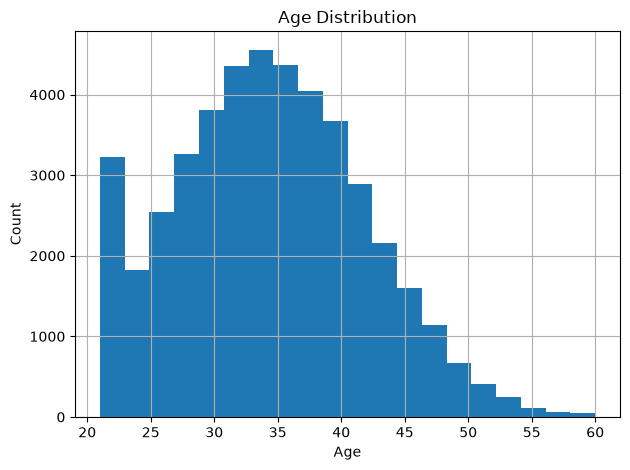

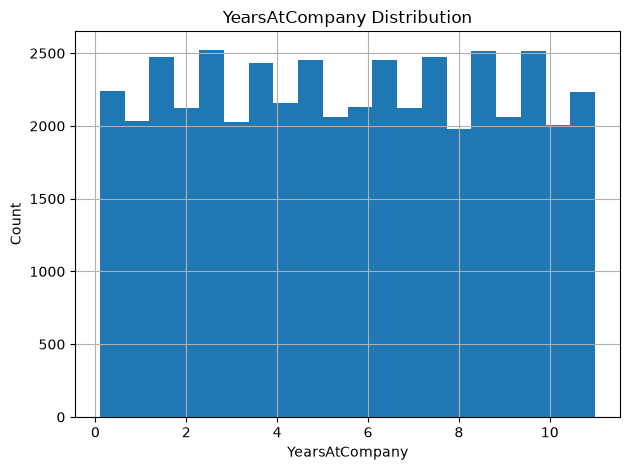

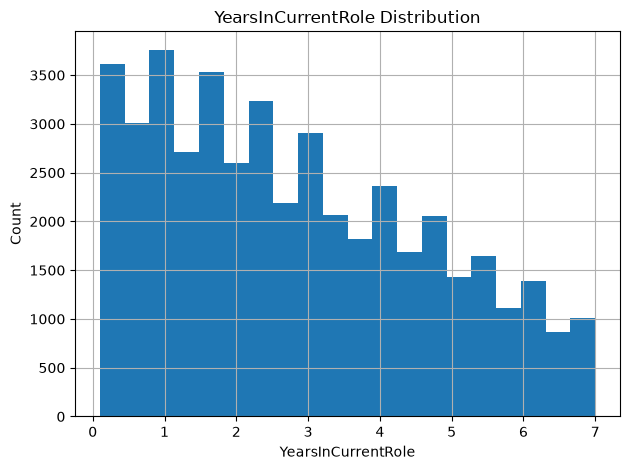

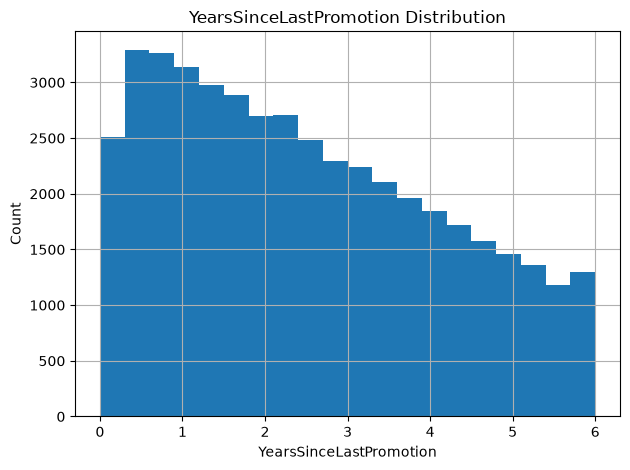

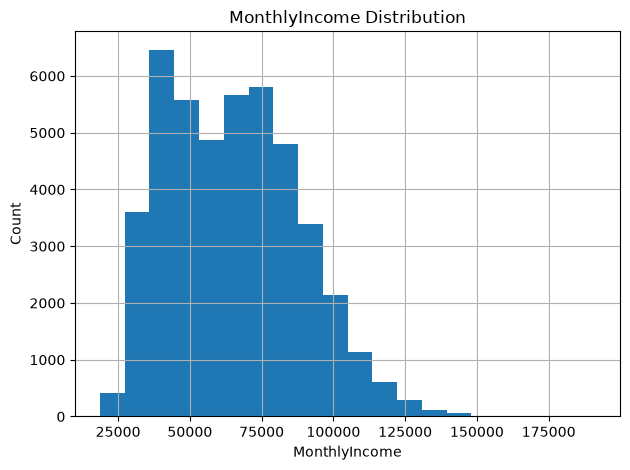

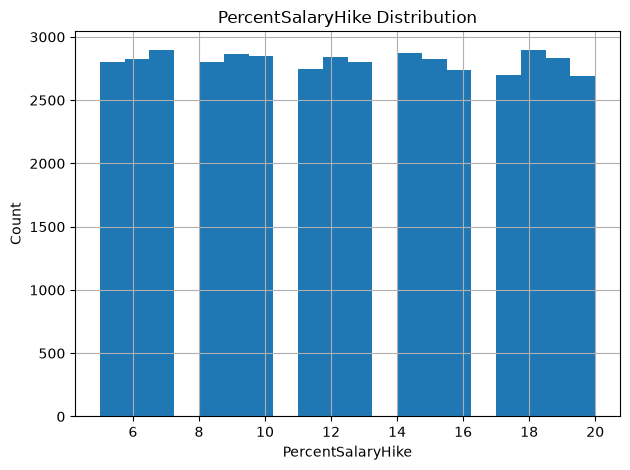

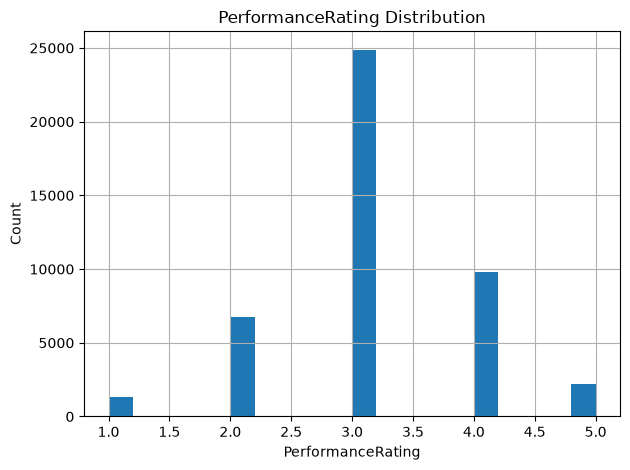

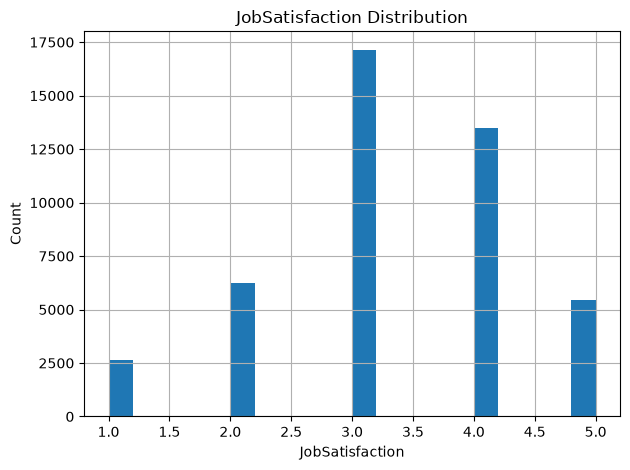

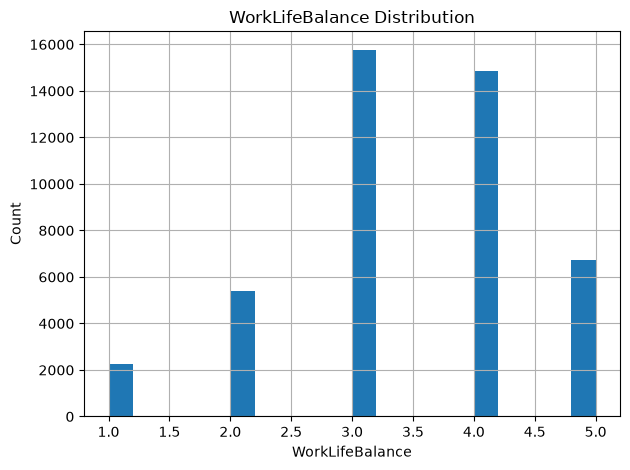

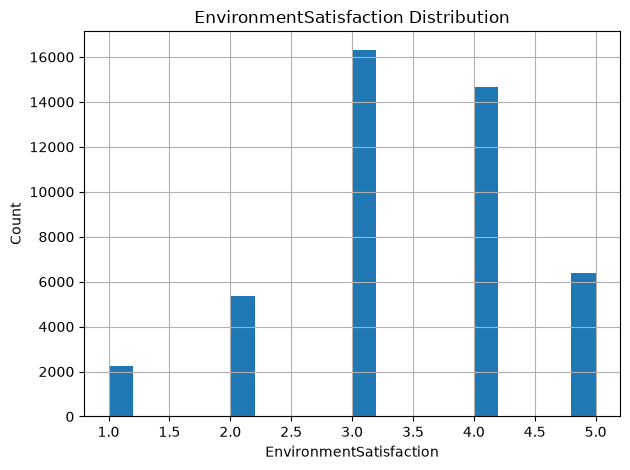

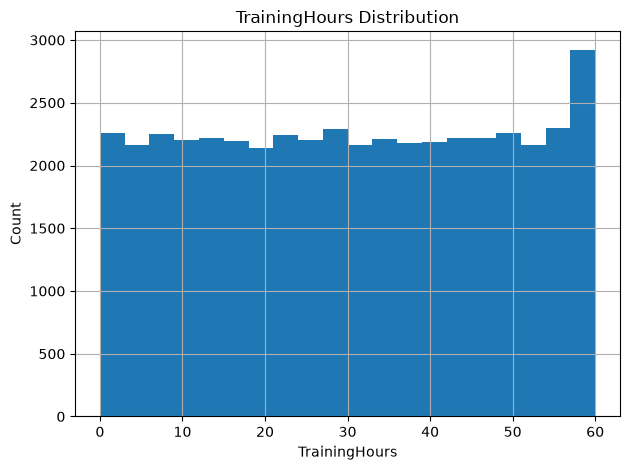

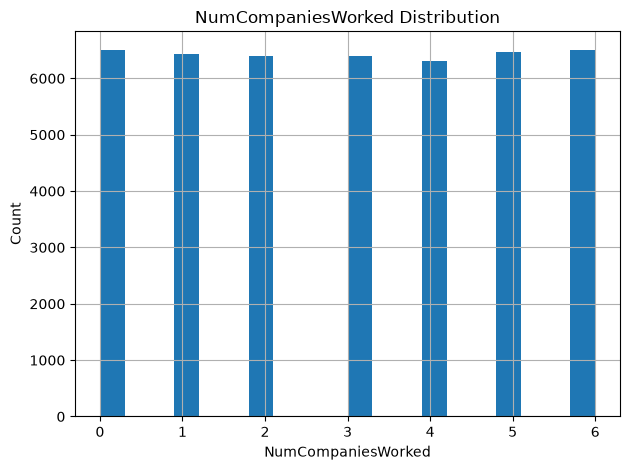

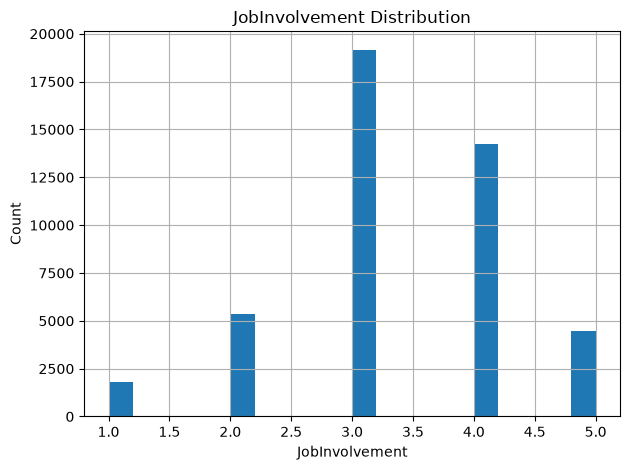

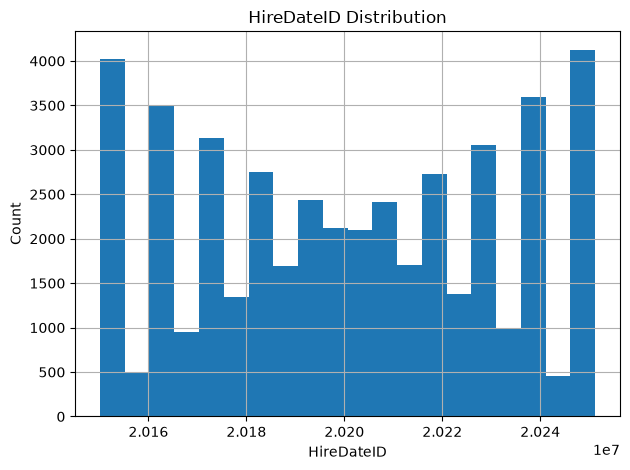

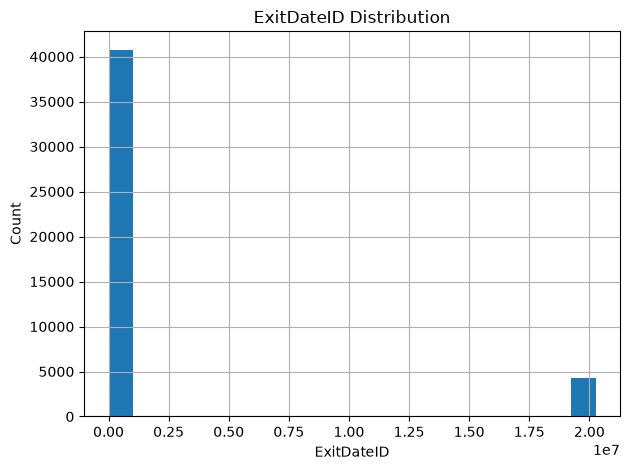

In [19]:
numeric_cols = dim_employee_snapshot.select_dtypes(
    include="number"
).columns

for col in numeric_cols:

    dim_employee_snapshot[col].hist(bins=20)

    plt.title(f"{col} Distribution")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

# 5 dim_job_role

 # Numeric columns

In [25]:
import matplotlib.pyplot as plt

numeric_cols = dim_job_role.select_dtypes(include="number").columns

print("Numeric Columns:")
print(numeric_cols.tolist())

Numeric Columns:
[]


In [26]:
for col in numeric_cols:

    plt.figure(figsize=(6, 4))

    plt.boxplot(dim_job_role[col].dropna())

    plt.title(f"{col} Box Plot")
    plt.ylabel(col)

    plt.show()

In [27]:
print(dim_employee.columns.tolist())

['EmployeeID', 'FirstName', 'LastName', 'Gender', 'Age', 'Education', 'EducationField', 'MaritalStatus', 'City', 'State', 'DepartmentID', 'JobRoleID', 'EmploymentType']


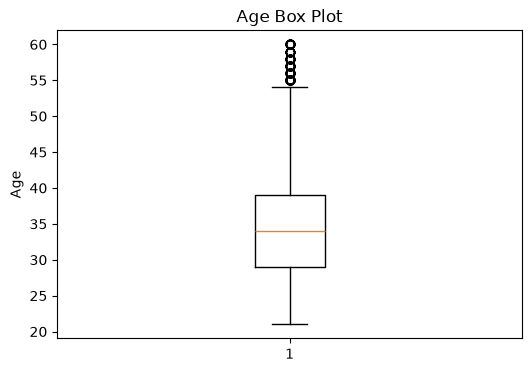

In [28]:
plt.figure(figsize=(6, 4))

plt.boxplot(dim_employee["Age"].dropna())

plt.title("Age Box Plot")
plt.ylabel("Age")

plt.show()

In [29]:
print("Shape:", dim_job_role.shape)

Shape: (23, 4)


In [30]:
print(dim_job_role.head())

  JobRoleID DepartmentGroup            JobRole DepartmentID
0      JR01              HR       HR Executive          D01
1      JR02              HR         HR Manager          D01
2      JR03         Finance  Financial Analyst          D02
3      JR04         Finance    Finance Manager          D02
4      JR05           Sales    Sales Executive          D03


In [31]:
print(dim_job_role.tail())

   JobRoleID DepartmentGroup                JobRole DepartmentID
18      JR19             R&D      Research Engineer          D08
19      JR20           Legal        Legal Associate          D09
20      JR21           Legal          Legal Manager          D09
21      JR22     Procurement  Procurement Executive          D10
22      JR23     Procurement    Procurement Manager          D10


# 6 fact_attrition

# Attrition distribution

In [32]:
import pandas as pd
from pathlib import Path

csv_path = Path.home() / "Desktop" / "csv"

fact_attrition = pd.read_csv(
    csv_path / "fact_attrition.csv"
)

print("fact_attrition imported successfully")
print(fact_attrition.shape)

fact_attrition imported successfully
(4231, 11)


# Numeric distributions


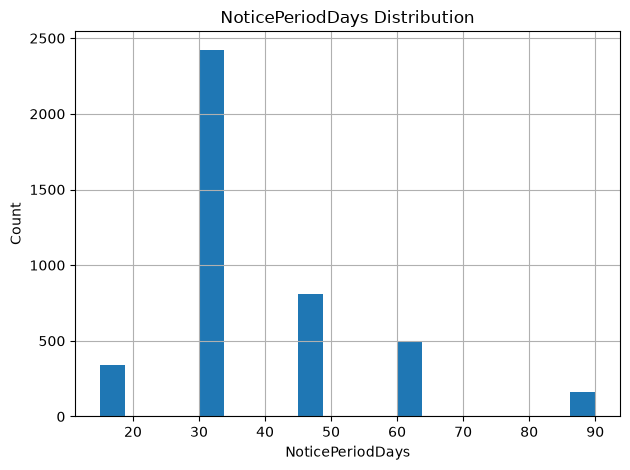

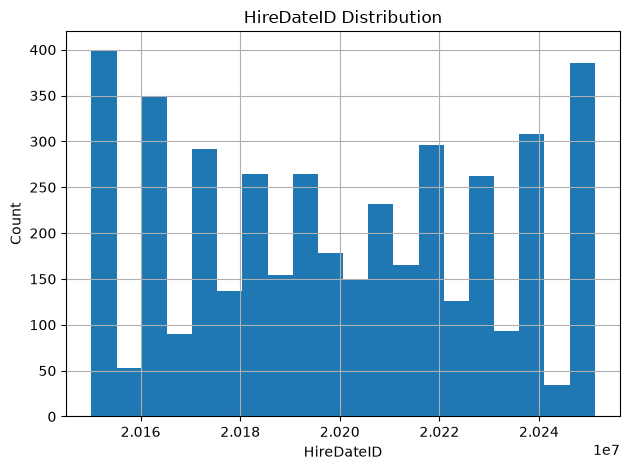

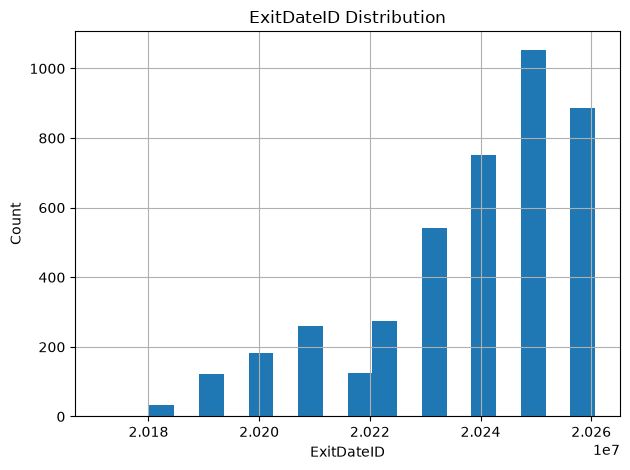

In [33]:
numeric_cols = fact_attrition.select_dtypes(
    include="number"
).columns

for col in numeric_cols:

    fact_attrition[col].hist(bins=20)

    plt.title(f"{col} Distribution")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

# Categorical analysis

In [34]:
categorical_cols = fact_attrition.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_cols:

    print(f"\n===== {col} =====")
    print(
        fact_attrition[col]
        .value_counts(dropna=False)
    )


===== EmployeeID =====
EmployeeID
E00007    1
E00012    1
E00019    1
E00047    1
E00062    1
         ..
E44964    1
E44965    1
E44984    1
E44989    1
E44991    1
Name: count, Length: 4231, dtype: int64

===== DepartmentID =====
DepartmentID
D05    760
D03    746
D07    566
D06    557
D04    340
D08    337
D02    297
D01    252
D10    236
D09    140
Name: count, dtype: int64

===== JobRoleID =====
JobRoleID
JR05    381
JR06    365
JR17    298
JR15    289
JR16    268
JR14    268
JR18    184
JR08    171
JR07    169
JR10    164
JR09    160
JR03    157
JR11    156
JR19    153
JR13    147
JR04    140
JR12    133
JR01    129
JR02    123
JR22    120
JR23    116
JR20     72
JR21     68
Name: count, dtype: int64

===== HireDate =====
HireDate
5/24/2022     7
12/14/2017    7
12/12/2017    6
6/25/2021     6
6/12/2022     6
             ..
1/22/2021     1
3/5/2025      1
10/12/2020    1
11/10/2018    1
9/12/2018     1
Name: count, Length: 2624, dtype: int64

===== ExitDate =====
ExitDate
5/11/

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_15952\2852976050.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = fact_attrition.select_dtypes(


# Numeric correlation

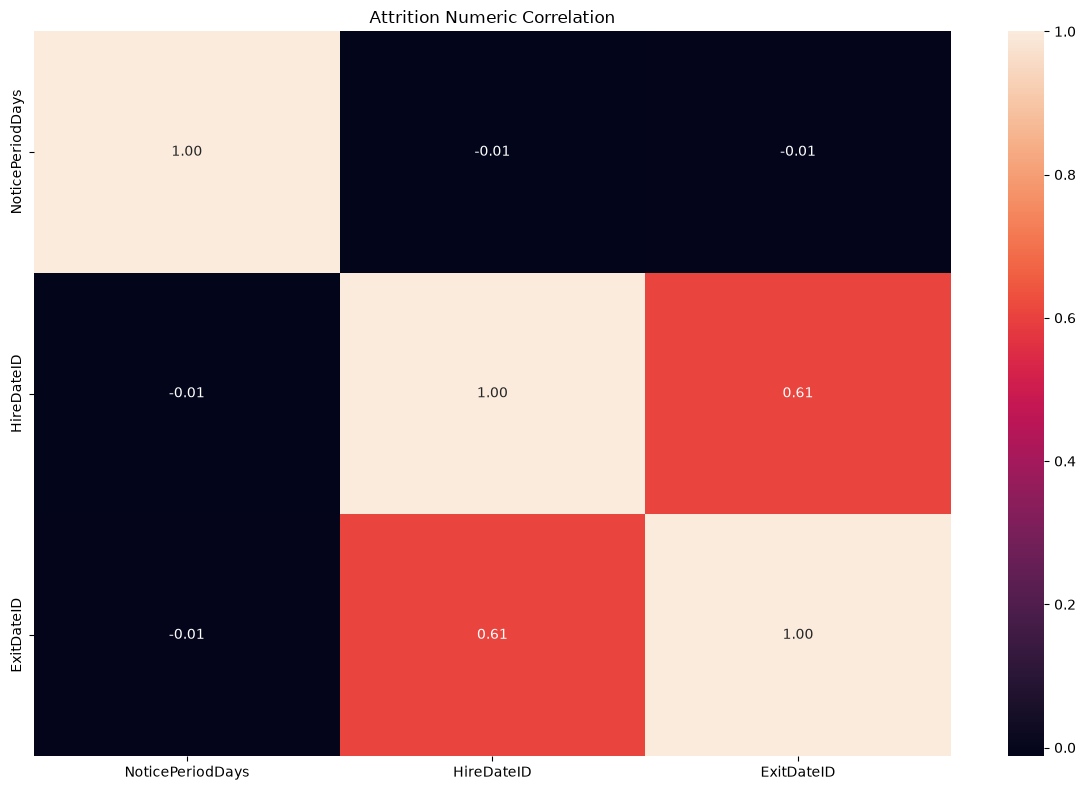

In [35]:
corr = fact_attrition.select_dtypes(
    include="number"
).corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f"
)

plt.title("Attrition Numeric Correlation")
plt.tight_layout()
plt.show()